# TransferIQ - training walkthrough
Runs locally (no Colab upload). The real logic lives in `src/train.py`; this notebook explains and visualises each step.

**Protocol:** 20% of players are held out as a test set and used once. Tuning and model selection use 5-fold CV on the other 80%. No early stopping on the test set.

In [1]:
import sys, json
from pathlib import Path
import pandas as pd, numpy as np
from IPython.display import Image, display
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / 'src'))
import train
pd.set_option('display.width', 160)

## 1. Data overview

In [2]:
df = train.load()
print(df.shape)
print('Missing values:', int(df.isna().sum().sum()))
df[train.TARGET].describe().round(2)

(450, 39)
Missing values: 0


count    450.00
mean      16.87
std        9.68
min        1.17
25%        9.85
50%       14.57
75%       21.85
max       61.25
Name: market_value_millions, dtype: float64

Market value is right-skewed (median well below the mean, a few very high values), which is why the target is log-transformed for training and converted back to EUR millions for every reported metric.

In [3]:
num = df.select_dtypes('number')
corr = num.corr()[train.TARGET].drop(train.TARGET).abs().sort_values(ascending=False)
corr.head(6).round(3)

performance_score         0.980
estimated_resale_value    0.943
defensive_index           0.837
goals_per_match           0.759
matches_played            0.719
minutes_played            0.688
Name: market_value_millions, dtype: float64

## 2. Leakage and duplicate checks
`performance_score` (0.98) and `estimated_resale_value` (0.94) are almost the target itself, so they are dropped. `discipline_index`, `injury_risk_assessment` and `injury_risk_score` are identical copies (correlation 1.0), as are `contract_end_year` and `years_remaining_contract`, so one of each is kept. Both lists are computed from the training portion only.

In [4]:
from sklearn.model_selection import train_test_split
dev, test = train_test_split(df, test_size=0.2, random_state=train.SEED)
proxies, redundant = train.drop_leaky_and_redundant(dev)
print('target proxies :', proxies)
print('duplicates     :', redundant)

target proxies : ['performance_score', 'estimated_resale_value']
duplicates     : ['discipline_index', 'injury_risk_assessment', 'years_remaining_contract']


## 3. Train, tune (5-fold CV) and evaluate
Five models: mean baseline, Ridge, Random Forest, XGBoost, LightGBM.

In [5]:
train.main()

Target proxies dropped: ['performance_score', 'estimated_resale_value']
Duplicate features dropped: ['discipline_index', 'injury_risk_assessment', 'years_remaining_contract']
dev=360 test=90 features=33
Mean baseline              CV R2 -0.072±0.058 MAE 6.83 | TEST R2 -0.100 MAE 8.60


Ridge (linear baseline)    CV R2 0.904±0.052 MAE 2.08 | TEST R2 0.955 MAE 1.83


Random Forest              CV R2 0.843±0.047 MAE 2.53 | TEST R2 0.908 MAE 2.27


XGBoost                    CV R2 0.873±0.049 MAE 2.24 | TEST R2 0.953 MAE 1.71


LightGBM                   CV R2 0.887±0.056 MAE 2.13 | TEST R2 0.953 MAE 1.72
Selected by CV MAE: Ridge (linear baseline)


ablation Ridge (linear baseline) | all features     CV R2 0.904 MAE 2.08
ablation Ridge (linear baseline) | without social   CV R2 0.903 MAE 2.08
ablation Ridge (linear baseline) | without injury   CV R2 0.900 MAE 2.08
ablation Ridge (linear baseline) | without contract CV R2 0.902 MAE 2.10
ablation LightGBM | all features                    CV R2 0.887 MAE 2.13
ablation LightGBM | without social                  CV R2 0.889 MAE 2.14
ablation LightGBM | without injury                  CV R2 0.887 MAE 2.13
ablation LightGBM | without contract                CV R2 0.887 MAE 2.15


{
  "selected_model": "Ridge (linear baseline)",
  "n_dev": 360,
  "n_test": 90,
  "n_features": 33,
  "target_proxies_dropped": [
    "performance_score",
    "estimated_resale_value"
  ],
  "duplicate_features_dropped": [
    "discipline_index",
    "injury_risk_assessment",
    "years_remaining_contract"
  ],
  "test": {
    "r2": 0.9546864506272132,
    "mae": 1.826997002664985,
    "rmse": 2.3675099969847024
  },
  "test_r2_95ci": [
    0.9359,
    0.9682
  ],
  "test_mae_95ci": [
    1.5179,
    2.1448
  ],
  "target_mean_dev": 16.596302983247224,
  "target_range": [
    1.167719314,
    61.2547141
  ],
  "ablation_cv(r2,mae)": {
    "Ridge (linear baseline) | all features": [
      0.9035,
      2.08
    ],
    "Ridge (linear baseline) | without social": [
      0.9032,
      2.084
    ],
    "Ridge (linear baseline) | without injury": [
      0.8999,
      2.081
    ],
    "Ridge (linear baseline) | without contract": [
      0.9018,
      2.1
    ],
    "LightGBM | all feature

## 4. Results

In [6]:
pd.read_csv(ROOT / 'results' / 'model_comparison.csv').drop(columns=['params']).round(3)

,model,cv_r2_mean,cv_r2_std,cv_mae_mean,cv_mae_std,cv_rmse_mean,test_r2,test_mae,test_rmse
0,Mean baseline,-0.072,0.058,6.834,1.015,9.376,-0.100,8.602,11.667
1,Ridge (linear baseline),0.904,0.052,2.080,0.195,2.625,0.955,1.827,2.368
2,Random Forest,0.843,0.047,2.534,0.307,3.481,0.908,2.274,3.376
3,XGBoost,0.873,0.049,2.235,0.235,3.084,0.953,1.710,2.400
4,LightGBM,0.887,0.056,2.132,0.189,2.862,0.954,1.725,2.399


In [7]:
m = json.load(open(ROOT / 'results' / 'metrics.json'))
print('Selected by CV MAE:', m['selected_model'])
print('Test metrics:', {k: round(v, 3) for k, v in m['test'].items()})
print('Test R2 95% CI:', m['test_r2_95ci'], '| Test MAE 95% CI:', m['test_mae_95ci'])
pd.DataFrame(m['ablation_cv(r2,mae)'], index=['CV R2', 'CV MAE']).T

Selected by CV MAE: Ridge (linear baseline)
Test metrics: {'r2': 0.955, 'mae': 1.827, 'rmse': 2.368}
Test R2 95% CI: [0.9359, 0.9682] | Test MAE 95% CI: [1.5179, 2.1448]


,CV R2,CV MAE
Ridge (linear baseline) | all features,0.9035,2.080
Ridge (linear baseline) | without social,0.9032,2.084
Ridge (linear baseline) | without injury,0.8999,2.081
Ridge (linear baseline) | without contract,0.9018,2.100
LightGBM | all features,0.8871,2.133
LightGBM | without social,0.8893,2.141
LightGBM | without injury,0.8874,2.131
LightGBM | without contract,0.8869,2.150


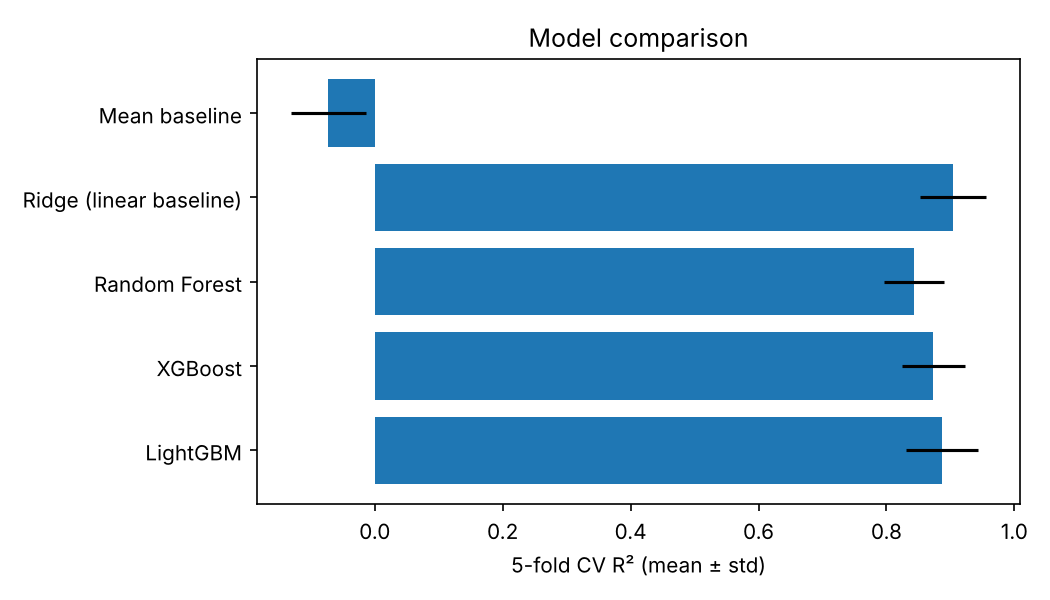

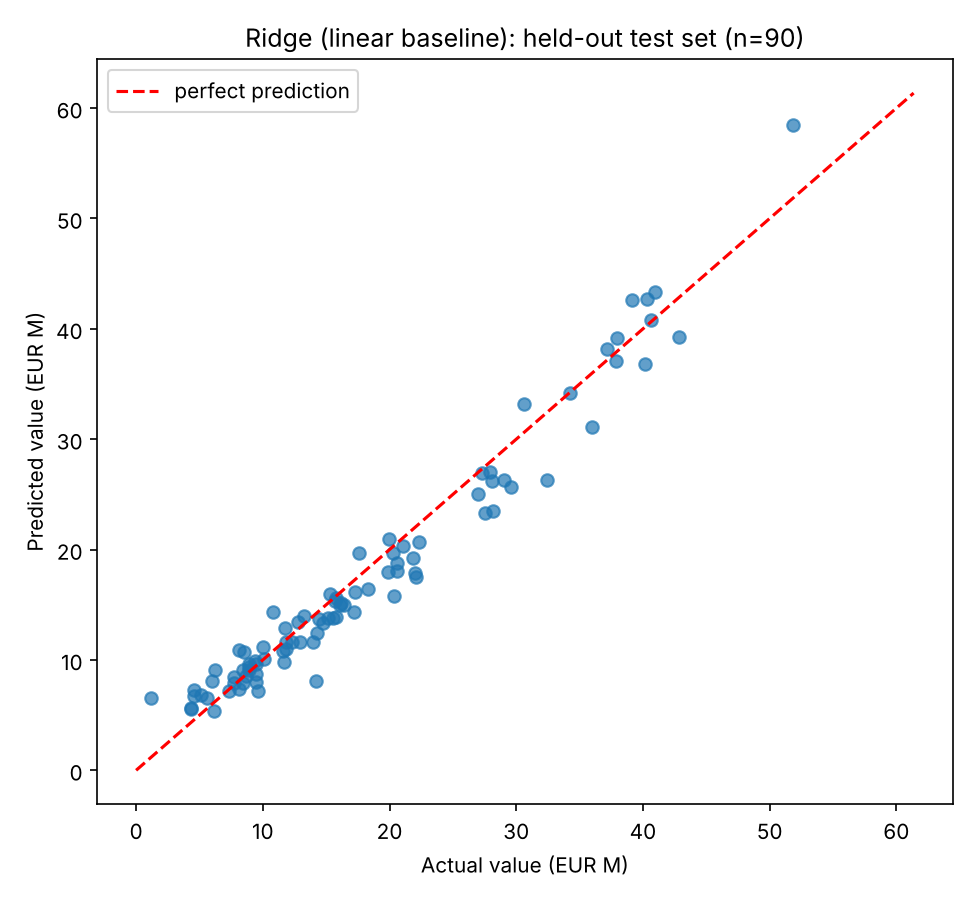

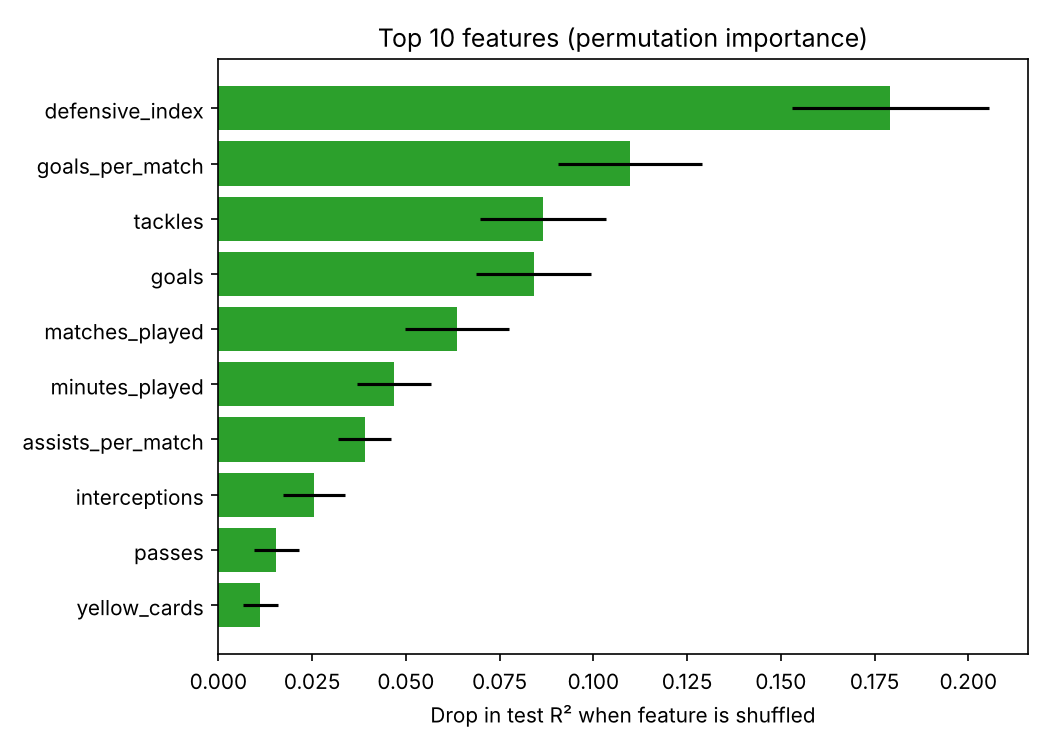

In [8]:
for f in ['model_comparison', 'actual_vs_predicted', 'feature_importance']:
    display(Image(str(ROOT / 'results' / f'{f}.png'), width=560))

## 5. Conclusions
- A regularised linear model on the log target performs about as well as XGBoost and LightGBM; the CV differences are smaller than the fold-to-fold spread. Random Forest is clearly behind.
- Removing the social-media, injury or contract features does not change CV performance for either the linear or the boosted model, so this dataset gives no evidence that they drive value. Performance statistics (defensive index, goals per match, tackles, goals) dominate.
- Test set is only 90 players, so test numbers carry wide intervals; CV is the more reliable estimate.